In [1]:
# 02 - SVM (TP3): SVM with a linear kernel and an RBF kernel, 3 folds (validation), 1 test, metrics, and MLflow
#
# STEP 1 - data analysis of the wavs (duration, quality) + why the prof's flatten()[:1200] is false
# STEP 2 - data cleaning: remove the broken wavs + the fixed TEST set of notebook 01 (20%, put aside)
# STEP 3 - data mining: which duration (2, 5 or 10 s) and which kernel give the best SVM on the Mel features?
#          (3 folds of the 80% train part, every test is saved in MLflow, with 1 small run per fold)
# STEP 4 - the results of the Mel features: linear vs rbf, the learning curves (training vs validation)
# STEP 5 - a second feature set: Zaineb's 72 features (merge of our 2 works) -> which feature set is the best?
# STEP 6 - VALIDATION of the chosen SVM: confusion matrix, ROC curve, learning curves of each fold
# STEP 7 - TEST: the final SVM (trained on the 80% part) is tested ONCE on the 20% test set, then saved in MLflow
#
# Before running: notebook 01 created ourdataset/train/normal/ and abnormal/ and splits/test_files.json,
# and the MLflow container must be running (docker start mlflow-server)

In [2]:
import os
import json
import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold            # to cut the dataset in 3 folds
from sklearn.model_selection import learning_curve   # the training vs validation curves (on the same 3 folds)
from sklearn.preprocessing import StandardScaler     # to put all the features on the same scale
from sklearn.svm import SVC                          # the SVM classifier
from sklearn.pipeline import make_pipeline           # the scaler + the SVM in one object (final model)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc           # the ROC curve and the area under it (AUC)

import mlflow
import mlflow.sklearn

In [3]:
# my folders (the same as in 01)
project_folder = "D:/MLOps_Project/"                        # the .data files are saved here
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)           # gives back what we saved


def save_data(data, file_name):
    with open(file_name, "wb") as f:    # "wb" = write binary
        pickle.dump(data, f)


# MLflow (Service 6): our server = the Docker container "mlflow-server", on port 5000
# audio_benchmark_final = ONE experiment for the 5 models with the final protocol (validation + test);
# the old runs stay in the experiment audio_benchmark (history)
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1795720788693, experiment_id='2', last_update_time=1795720788693, lifecycle_stage='active', name='audio_benchmark_final', tags={}>

In [4]:
# ==================== STEP 1 - Data analysis of the wavs (before making any feature) ====================
SR = 2000    # every wav is read at 2000 Hz (the sample rate of PhysioNet: heart sounds are below 1000 Hz)


def wav_info(file, class_name):
    signal, rate = librosa.load(file, sr=SR)
    return {
        "file": file,
        "class": class_name,
        "label": 1 if class_name == "abnormal" else 0,
        "duration": len(signal) / rate,                               # in seconds
        "peak": np.max(np.abs(signal)),                               # the loudest sample (1 = the maximum): ~0 = no sound
        "clipping_pct": 100 * np.mean(np.abs(signal) >= 0.99),        # % of saturated samples (sound too loud)
    }


rows = []
for class_name in ["abnormal", "normal"]:
    for file in glob(ourdataset_folder + class_name + "/*.wav"):
        rows.append(wav_info(file, class_name))

wavs_info = pd.DataFrame(rows)    # a table: 1 row per wav
print(len(wavs_info), "wavs")
ipd.display(wavs_info.groupby("class")[["duration", "peak", "clipping_pct"]].agg(["min", "median", "max"]).round(3))

3766 wavs


duration                    peak               clipping_pct         \
              min  median      max    min median    max          min median   
class                                                                         
abnormal    0.857  20.724  121.998  0.023  0.917  1.196          0.0    0.0   
normal      0.764  18.606  101.673  0.019  0.856  1.465          0.0    0.0   

                  
             max  
class             
abnormal   9.025  
normal    10.926

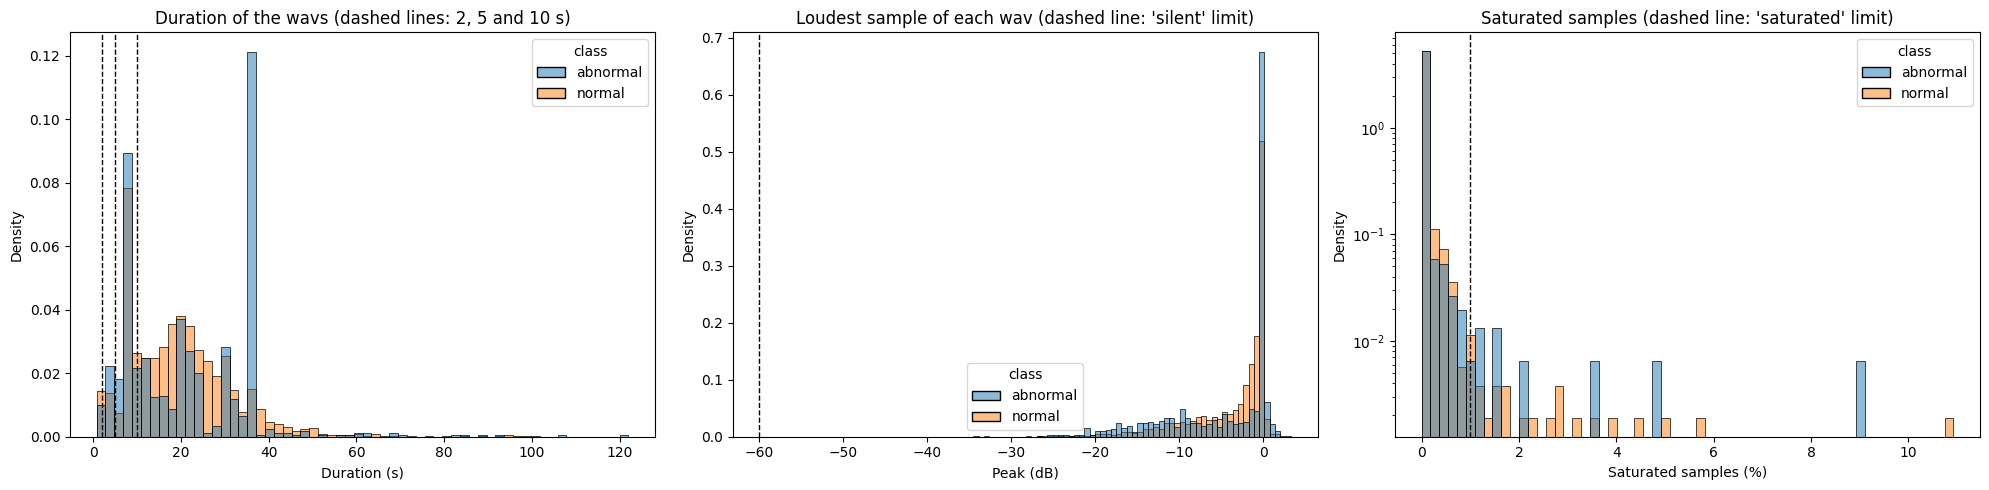

Broken wavs found by each rule:


,too_short,silent,saturated
class,,,
abnormal,5,0,9
normal,50,0,22


In [5]:
# the rules for a "broken" wav (you can change these numbers)
MIN_DURATION = 2       # seconds: less than ~2 heartbeats
MIN_PEAK = 0.001       # almost no sound at all (-60 dB)
MAX_CLIPPING = 1       # more than 1% of the samples are saturated

wavs_info["too_short"] = wavs_info["duration"] < MIN_DURATION
wavs_info["silent"] = wavs_info["peak"] < MIN_PEAK
wavs_info["saturated"] = wavs_info["clipping_pct"] > MAX_CLIPPING
wavs_info["peak_db"] = 20 * np.log10(np.maximum(wavs_info["peak"], 1e-6))    # the peak in dB (0 dB = the maximum)

# ONE figure: the duration, the loudness and the saturation of the wavs, normal vs abnormal
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
sns.histplot(data=wavs_info, x="duration", hue="class", bins=60, stat="density", common_norm=False)
for seconds in [2, 5, 10]:
    plt.axvline(seconds, color="black", linestyle="--", linewidth=1)
plt.title("Duration of the wavs (dashed lines: 2, 5 and 10 s)")
plt.xlabel("Duration (s)")

plt.subplot(1, 3, 2)
sns.histplot(data=wavs_info, x="peak_db", hue="class", bins=60, stat="density", common_norm=False)
plt.axvline(20 * np.log10(MIN_PEAK), color="black", linestyle="--", linewidth=1)
plt.title("Loudest sample of each wav (dashed line: 'silent' limit)")
plt.xlabel("Peak (dB)")

plt.subplot(1, 3, 3)
sns.histplot(data=wavs_info, x="clipping_pct", hue="class", bins=60, stat="density", common_norm=False)
plt.axvline(MAX_CLIPPING, color="black", linestyle="--", linewidth=1)
plt.yscale("log")
plt.title("Saturated samples (dashed line: 'saturated' limit)")
plt.xlabel("Saturated samples (%)")

plt.tight_layout()
plt.show()

print("Broken wavs found by each rule:")
ipd.display(wavs_info.groupby("class")[["too_short", "silent", "saturated"]].sum())

30.0 s -> table of 128 bands x 1292 moments -> the 1200 numbers = 0.9 band(s)
0.8 s -> table of 128 bands x 33 moments -> the 1200 numbers = 36.4 band(s)


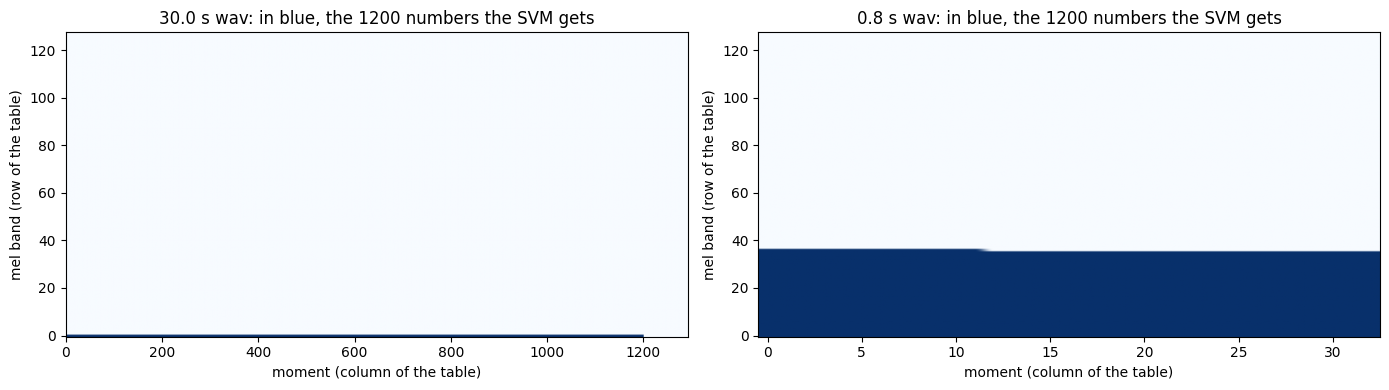

In [6]:
# What is inside theflatten()[:1200]? (his Mel spectrogram: 22050 Hz, 128 bands)
def prof_mel(file):
    signal, rate = librosa.load(file)
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=2048, hop_length=512, n_mels=128)
    return librosa.power_to_db(S, ref=np.max)


long_index = np.argmin(np.abs(wavs_info["duration"] - 30))    # a wav of about 30 seconds
short_index = np.argmin(wavs_info["duration"])                 # the shortest wav

plt.figure(figsize=(14, 4))
place = 1
for index in [long_index, short_index]:
    file = wavs_info["file"][index]
    duration = wavs_info["duration"][index]
    S_DB = prof_mel(file)                     # a table: 128 bands x 1 column per moment
    used = np.zeros(S_DB.size)
    used[:1200] = 1                           # flatten()[:1200] = the first 1200 numbers, read band after band
    used = used.reshape(S_DB.shape)           # put them back in the table to see WHERE they are
    print("{:.1f} s -> table of {} bands x {} moments -> the 1200 numbers = {:.1f} band(s)".format(
        duration, S_DB.shape[0], S_DB.shape[1], 1200 / S_DB.shape[1]))

    plt.subplot(1, 2, place)
    plt.imshow(used, aspect="auto", origin="lower", cmap="Blues")
    plt.title("{:.1f} s wav: in blue, the 1200 numbers the SVM gets".format(duration))
    plt.xlabel("moment (column of the table)")
    plt.ylabel("mel band (row of the table)")
    place = place + 1

plt.tight_layout()
plt.show()
# -> for a long wav the 1200 numbers are ONLY the lowest band (murmurs are in higher bands), for a short wav
#    they are many bands: number 500 does not mean the same thing for 2 wavs -> false.
#    Correction (STEP 3): the same duration and the same sample rate for every wav

In [7]:
# ==================== STEP 2 - Data cleaning: remove the broken wavs ====================
# the SAME rules for normal and abnormal (decided without looking at the class),
# so later the audio engine can check a new wav with the same rules
bad = wavs_info["too_short"] | wavs_info["silent"] | wavs_info["saturated"]
clean = wavs_info[~bad].reset_index(drop=True)    # ~ = "not": we keep the wavs that are NOT bad

print("removed:", bad.sum(), "wavs ->", wavs_info[bad]["class"].value_counts().to_dict())
print("kept:", len(clean), "wavs -> normal:", (clean["label"] == 0).sum(), "| abnormal:", (clean["label"] == 1).sum())

removed: 85 wavs -> {'normal': 71, 'abnormal': 14}
kept: 3681 wavs -> normal: 2855 | abnormal: 826


In [8]:
# ==================== The fixed TEST set (made by notebook 01): put aside, never used to train ====================
# - 80% = the TRAIN part: STEPS 3 to 6 (the choice of the duration, the kernel, the features, and the 3 folds)
# - 20% = the TEST part: used ONCE at the end (STEP 7), to test the final SVM
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
test_label = dict(zip(split["test_files"], split["test_labels"]))    # name of a test wav -> its class

clean["name"] = clean["file"].apply(os.path.basename)                # "a0001.wav", ...
is_test = clean["name"].isin(test_label).values                      # True for the 20% test wavs
assert is_test.sum() == split["n_test"], "some test wavs are missing: run notebook 01 again"
for i in np.where(is_test)[0]:
    assert clean["label"][i] == test_label[clean["name"][i]], "the class of a test wav is not the same in notebook 01"
print("train (80%):", np.sum(~is_test), "wavs | test (20%):", np.sum(is_test), "wavs")

train (80%): 2944 wavs | test (20%): 737 wavs


In [9]:
# ==================== The features: the Mel spectrogram of EACH wav ====================
#   1. every wav at 2000 Hz
#   2. every wav = exactly the same duration: the middle part (the start is often noisy, when the
#      stethoscope is placed); a shorter wav is repeated until it is long enough
#   3. Mel spectrogram: 30 bands, windows of 256 samples (0.128 s) -> a table of 30 bands x N moments
#   4. flatten() -> number i = the SAME band at the SAME moment for every wav
N_MELS = 30
N_FFT = 256
HOP_LENGTH = 256


def get_mel_features(file, seconds):
    n_samples = SR * seconds
    signal, rate = librosa.load(file, sr=SR)

    if len(signal) < n_samples:
        repeat = int(np.ceil(n_samples / len(signal)))
        signal = np.tile(signal, repeat)[:n_samples]       # too short: repeat the heartbeats
    else:
        start = (len(signal) - n_samples) // 2
        signal = signal[start:start + n_samples]           # too long: keep the middle part

    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    S_DB = librosa.power_to_db(S, ref=np.max)    # a table of 30 bands x N moments, in dB
    #ref=np.max makes each wav’s loudest point 0 dB, so the recording volume doesn’t matter.
    return S_DB.flatten()


def build_features(seconds):
    X = []
    for file in clean["file"]:               # only the clean wavs
        X.append(get_mel_features(file, seconds))
    return np.array(X), clean["label"].values

In [10]:
# The 3 folds, with the example of the TP: 10 wavs numbered 1 to 10
# each fold: 1 third of the wavs = test (33%), the 2 other thirds = train (66%)
# each fold takes a DIFFERENT third for the test -> every wav is tested exactly once
def show_folds(kfold, items):
    fold = 1
    for train_index, test_index in kfold.split(items):
        print("  Fold", fold, ": test =", items[test_index], "  train =", items[train_index])
        fold = fold + 1


items = np.arange(1, 11)    # [ 1  2  3  4  5  6  7  8  9 10]

print("In order (like the example of the TP):")
show_folds(KFold(n_splits=3), items)
# 10 can't be cut in 3 equal parts, so the first test has 4 wavs (then wav 10 is tested too)

print("At random (random1 # random2: a different random third each time):")
show_folds(KFold(n_splits=3, shuffle=True, random_state=1), items)
# In this notebook the 3 folds cut the 80% TRAIN part: the "test" third of a fold is called VALIDATION

In order (like the example of the TP):
  Fold 1 : test = [1 2 3 4]   train = [ 5  6  7  8  9 10]
  Fold 2 : test = [5 6 7]   train = [ 1  2  3  4  8  9 10]
  Fold 3 : test = [ 8  9 10]   train = [1 2 3 4 5 6 7]
At random (random1 # random2: a different random third each time):
  Fold 1 : test = [ 3  5  7 10]   train = [1 2 4 6 8 9]
  Fold 2 : test = [1 2 4]   train = [ 3  5  6  7  8  9 10]
  Fold 3 : test = [6 8 9]   train = [ 1  2  3  4  5  7 10]


In [11]:
# The TP3 method in ONE function: 3 folds, and for each fold: split -> scale -> train the SVM -> predict -> metrics
kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the SAME 3 random folds every time (fair comparison)


def evaluate_svm(X, y, kernel):
    folds = []
    fold = 1
    for train_index, val_index in kfold.split(X):
        # 1. split: 2 thirds of the wavs to train (66%), 1 third to validate (33%)
        X_tr, X_val = X[train_index], X[val_index]
        y_tr, y_val = y[train_index], y[val_index]

        # 2. same scale for every feature (mean 0, std 1), learned on the TRAIN only:
        #    the validation wavs stay "never seen"
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_val = scaler.transform(X_val)

        # 3. train the SVM, then ask it the class of the validation wavs
        #    class_weight="balanced": 3.5x more normal wavs than abnormal ones, so a mistake on an
        #    abnormal wav counts 3.5x more (if not, the SVM says "normal" too often)
        model = SVC(kernel=kernel, class_weight="balanced")
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        y_score = model.decision_function(X_val)    # the signed distance to the border (> 0 = abnormal): for the ROC
        y_tr_pred = model.predict(X_tr)             # also on its own train wavs: to compare training vs validation
        false_positive_rate, true_positive_rate, thresholds = roc_curve(y_val, y_score)

        # 4. metrics (precision, recall, f1: for the abnormal class)
        folds.append({
            "fold": fold,
            "accuracy": accuracy_score(y_val, y_pred),
            "precision": precision_score(y_val, y_pred),
            "recall": recall_score(y_val, y_pred),
            "f1": f1_score(y_val, y_pred),
            "auc": auc(false_positive_rate, true_positive_rate),
            "train_accuracy": accuracy_score(y_tr, y_tr_pred),    # the same 4 metrics on the train wavs
            "train_precision": precision_score(y_tr, y_tr_pred),
            "train_recall": recall_score(y_tr, y_tr_pred),
            "train_f1": f1_score(y_tr, y_tr_pred),
            "y_val": y_val,      # kept to show the details in STEPS 4 and 6
            "y_pred": y_pred,
            "y_score": y_score,
        })
        fold = fold + 1
    return folds


metrics = ["accuracy", "precision", "recall", "f1", "auc"]


def log_validation_run(run_name, kernel, features_text, seconds, n_features, folds):
    # 1 MLflow run per setting (validation only: the 3 folds of the train part), + 1 small run per fold inside it
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_param("model", "SVM")
        mlflow.log_param("kernel", kernel)
        mlflow.log_param("class_weight", "balanced")
        mlflow.log_param("n_folds", 3)
        mlflow.log_param("features", features_text)
        mlflow.log_param("seconds", seconds)
        mlflow.log_param("sample_rate", SR)
        mlflow.log_param("n_features", n_features)
        mlflow.log_param("n_train", int(np.sum(~is_test)))
        for metric in metrics:
            mlflow.log_metric("mean_" + metric, np.mean([f[metric] for f in folds]))
        for f in folds:    # the results of each fold, also here: fold1_accuracy, fold1_precision, ..., fold3_auc
            for metric in metrics:
                mlflow.log_metric("fold" + str(f["fold"]) + "_" + metric, f[metric])

        # the 3 folds: 1 small run per fold INSIDE this run (nested=True), with its training and validation results
        for f in folds:
            with mlflow.start_run(run_name=run_name + "_fold" + str(f["fold"]), nested=True):
                mlflow.log_param("fold", f["fold"])
                for metric in ["accuracy", "precision", "recall", "f1"]:
                    mlflow.log_metric("train_" + metric, f["train_" + metric])    # on the 2/3 train wavs
                    mlflow.log_metric("val_" + metric, f[metric])                 # on the 1/3 validation wavs
                mlflow.log_metric("val_auc", f["auc"])
    return run.info.run_id

2 s -> 480 features per wav ( 30 bands x 16 moments )


🏃 View run svm_linear_2s_fold1 at: http://localhost:5000/#/experiments/2/runs/3e844653e3a44826b70185af9fa1758d
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_linear_2s_fold2 at: http://localhost:5000/#/experiments/2/runs/7c6541984bb44f6f88324a42d131036a
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_linear_2s_fold3 at: http://localhost:5000/#/experiments/2/runs/7daa9995ad114e9fa7dd8b2202345ae6
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_linear_2s at: http://localhost:5000/#/experiments/2/runs/2987f3d10b2d4e6290dcdafb37ca1b61
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_2s_fold1 at: http://localhost:5000/#/experiments/2/runs/267a1465fc634396aa784a43597e4e77
🧪 View experiment at: http://localhost:5000/#/experiments/2


... (20 outputs left out)

🏃 View run svm_rbf_10s at: http://localhost:5000/#/experiments/2/runs/bbfa8b9b7d2c460d931d17a8b9ec467b
🧪 View experiment at: http://localhost:5000/#/experiments/2


Mean of the 3 folds (validation):


accuracy  precision  recall     f1    auc
seconds kernel                                           
2       linear     0.712      0.398   0.548  0.461  0.718
        rbf        0.787      0.516   0.840  0.639  0.879
5       linear     0.732      0.412   0.453  0.431  0.708
        rbf        0.791      0.521   0.826  0.639  0.884
10      linear     0.742      0.422   0.405  0.413  0.723
        rbf        0.783      0.511   0.808  0.626  0.877

Best duration: 2 s (F1 0.639 | recall 0.84 with the rbf kernel)


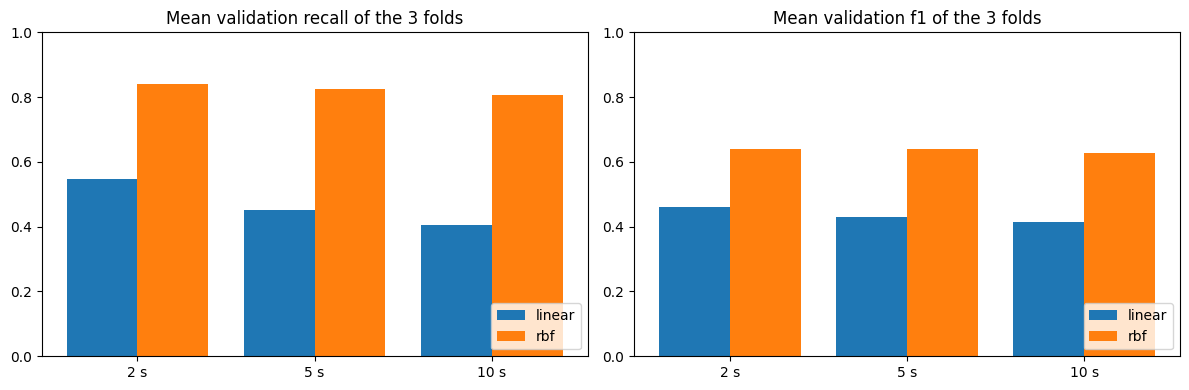

In [12]:
# ==================== STEP 3 - Which duration is the best? (data mining, on the 80% train part) ====================
# For 2, 5 and 10 seconds: make the features, test the SVM (2 kernels x 3 folds), save the test in MLflow.
# It takes several minutes.
durations_to_test = [2, 5, 10]
kernels = ["linear", "rbf"]
y_train = clean["label"].values[~is_test]
y_test = clean["label"].values[is_test]

features = {}       # the features of each duration (to reuse them after)
results = []        # 1 line per (duration, kernel, fold)
predictions = {}    # the predictions of each fold, for STEP 4
run_ids = {}        # the MLflow run of each setting, to add the final model in STEP 7

for seconds in durations_to_test:
    X, y = build_features(seconds)
    features[seconds] = X
    print(seconds, "s ->", X.shape[1], "features per wav (", N_MELS, "bands x", X.shape[1] // N_MELS, "moments )")

    for kernel in kernels:
        folds = evaluate_svm(X[~is_test], y_train, kernel)    # only the 80% train part
        predictions[(seconds, kernel)] = folds
        for f in folds:
            results.append({"seconds": seconds, "kernel": kernel, "fold": f["fold"], "accuracy": f["accuracy"],
                            "precision": f["precision"], "recall": f["recall"], "f1": f["f1"], "auc": f["auc"]})
        run_ids[("mel", seconds, kernel)] = log_validation_run(
            "svm_" + kernel + "_" + str(seconds) + "s", kernel, "mel spectrogram flatten (30 bands)", seconds,
            X.shape[1], folds)

table = pd.DataFrame(results)
summary = table.groupby(["seconds", "kernel"])[["accuracy", "precision", "recall", "f1", "auc"]].mean().round(3)
print("Mean of the 3 folds (validation):")
ipd.display(summary)

# the best duration = the highest F1 of abnormal. F1 balances the recall (find the sick hearts) and the
# precision (not too many false alarms): with the recall alone, a model that says "abnormal" too often would win
best = summary["f1"].idxmax()              # (seconds, kernel)
best_seconds = best[0]
print("Best duration:", best_seconds, "s (F1", summary.loc[best, "f1"], "| recall", summary.loc[best, "recall"],
      "with the", best[1], "kernel)")

# recall and F1 of each duration, linear vs rbf
plt.figure(figsize=(12, 4))
x = np.arange(len(durations_to_test))
for place, metric in [(1, "recall"), (2, "f1")]:
    plt.subplot(1, 2, place)
    plt.bar(x - 0.2, [summary.loc[(s, "linear"), metric] for s in durations_to_test], width=0.4, label="linear")
    plt.bar(x + 0.2, [summary.loc[(s, "rbf"), metric] for s in durations_to_test], width=0.4, label="rbf")
    plt.xticks(x, [str(s) + " s" for s in durations_to_test])
    plt.ylim(0, 1)
    plt.title("Mean validation " + metric + " of the 3 folds")
    plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:
# the features of the best duration, saved like the prof (a = the features, b = the classes) + the wav names
X = features[best_seconds]
save_data(list(X), project_folder + "mel_features_svm_a.data")
save_data(list(clean["label"].values), project_folder + "mel_features_svm_b.data")
save_data(list(clean["name"]), project_folder + "svm_files.data")
print("X:", X.shape, "->", X.shape[0], "wavs,", X.shape[1], "features | normal:", np.sum(clean["label"] == 0),
      "| abnormal:", np.sum(clean["label"] == 1))

X: (3681, 480) -> 3681 wavs, 480 features | normal: 2855 | abnormal: 826


In [14]:
# ==================== STEP 4 - The results of the Mel features (with the best duration) ====================
final_results = []         # 1 line per (kernel, fold)
confusion_matrices = []    # for the figure

for kernel in kernels:
    print("==================== SVM with kernel =", kernel, "-", best_seconds, "s ====================")
    for f in predictions[(best_seconds, kernel)]:
        print("--- Fold", f["fold"], ": validation =", len(f["y_val"]), "wavs")
        print(classification_report(f["y_val"], f["y_pred"], target_names=["normal", "abnormal"]))
        confusion_matrices.append(confusion_matrix(f["y_val"], f["y_pred"]))
        final_results.append({"kernel": kernel, "fold": f["fold"], "accuracy": f["accuracy"],
                              "precision": f["precision"], "recall": f["recall"], "f1": f["f1"], "auc": f["auc"]})

final_table = pd.DataFrame(final_results)
ipd.display(final_table.round(3))
print("Mean of the 3 folds (like the example: (0.7 + 0.8 + 0.9) / 3 = 0.8):")
ipd.display(final_table.groupby("kernel")[["accuracy", "precision", "recall", "f1", "auc"]].mean().round(3))

==================== SVM with kernel = linear - 2 s ====================
--- Fold 1 : validation = 982 wavs
              precision    recall  f1-score   support

      normal       0.85      0.78      0.81       756
    abnormal       0.42      0.53      0.47       226

    accuracy                           0.72       982
   macro avg       0.63      0.65      0.64       982
weighted avg       0.75      0.72      0.73       982

--- Fold 2 : validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.86      0.75      0.80       759
    abnormal       0.40      0.57      0.47       222

    accuracy                           0.71       981
   macro avg       0.63      0.66      0.63       981
weighted avg       0.75      0.71      0.72       981

--- Fold 3 : validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.86      0.75      0.80       768
    abnormal       0.38      0.54      0.45       213

    

,kernel,fold,accuracy,precision,recall,f1,auc
0,linear,1,0.721,0.417,0.531,0.467,0.727
1,linear,2,0.708,0.399,0.568,0.468,0.730
2,linear,3,0.707,0.379,0.545,0.447,0.698
3,rbf,1,0.807,0.551,0.858,0.671,0.889
4,rbf,2,0.775,0.501,0.820,0.622,0.875
5,rbf,3,0.779,0.494,0.840,0.623,0.872


Mean of the 3 folds (like the example: (0.7 + 0.8 + 0.9) / 3 = 0.8):


,accuracy,precision,recall,f1,auc
kernel,,,,,
linear,0.712,0.398,0.548,0.461,0.718
rbf,0.787,0.516,0.840,0.639,0.879


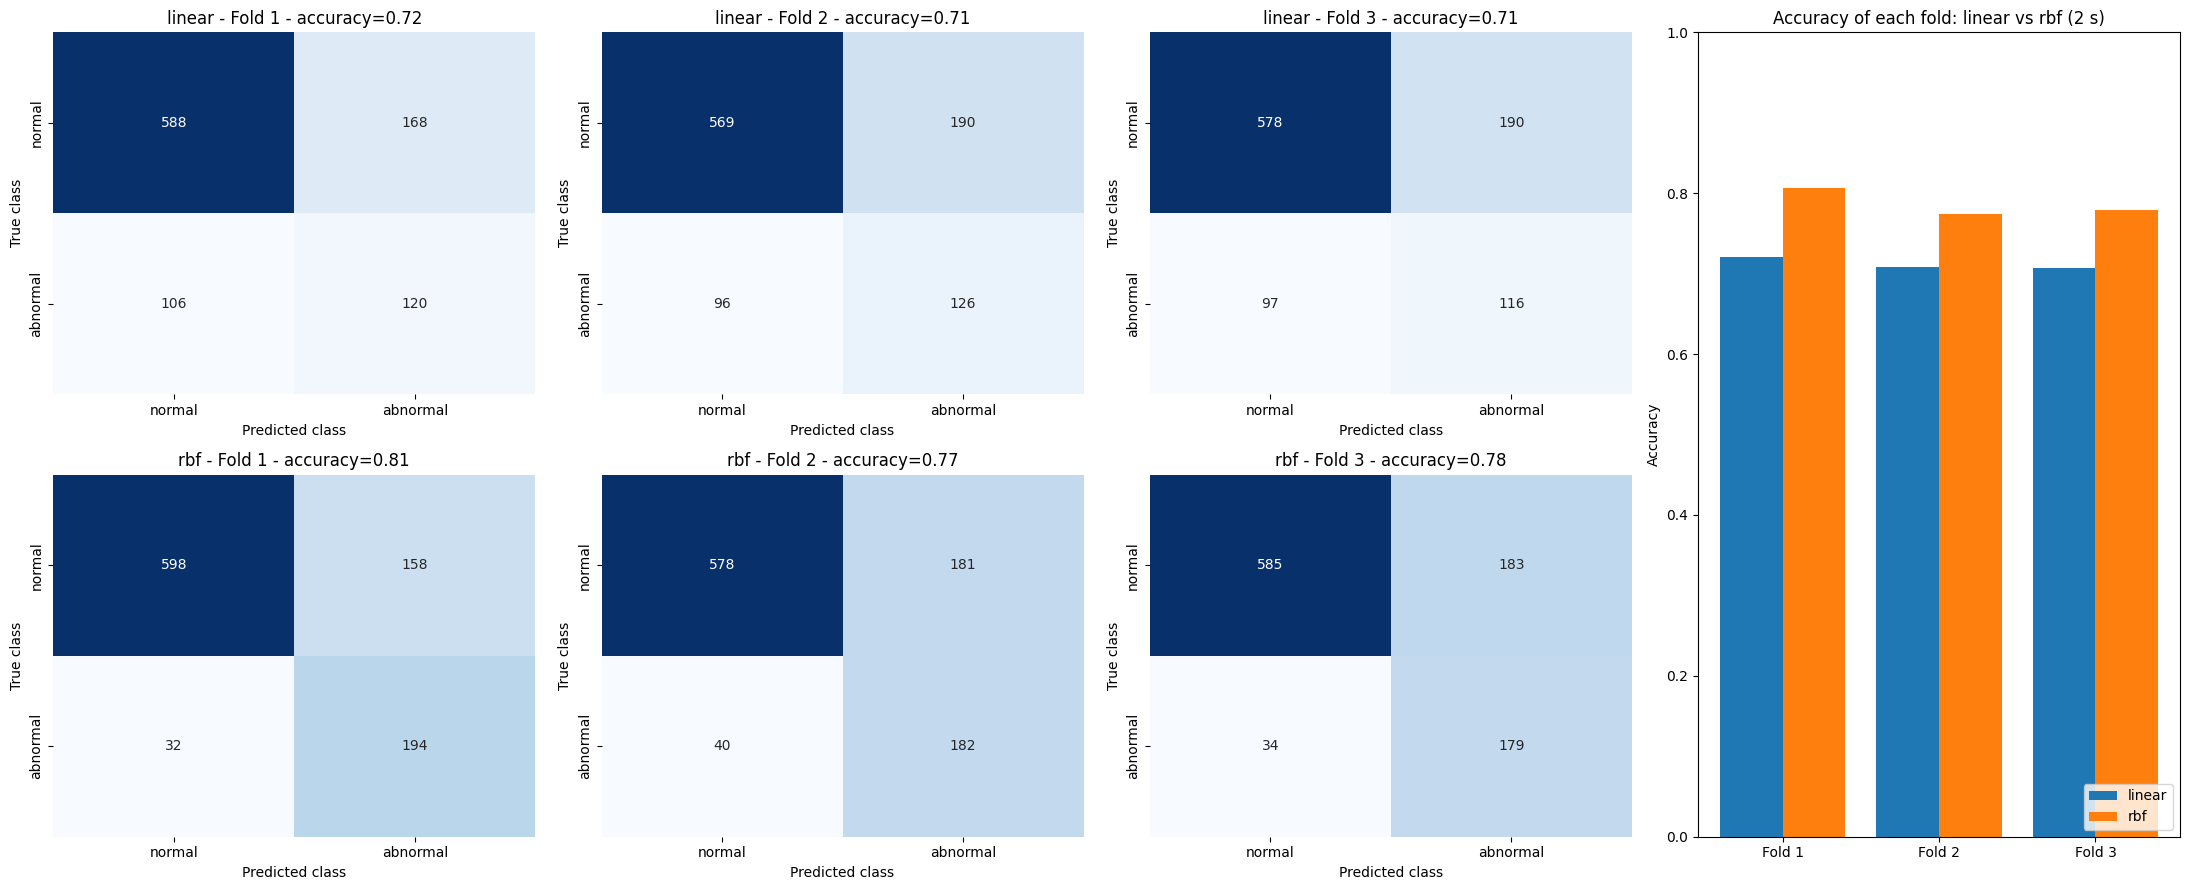

In [15]:
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of wavs of class i (true) that the SVM put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    # ROC curve: for every threshold, the % of sick hearts found (true positive rate = recall) against the % of
    # normal hearts called abnormal (false positive rate). AUC = the area under it (1 = perfect, 0.5 = random)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")
    return area


# ONE figure: 2 rows (linear, rbf) x 4 columns (fold 1, fold 2, fold 3, accuracy)
plt.figure(figsize=(22, 9))

places = [1, 2, 3, 5, 6, 7]    # the 6 confusion matrices: linear fold 1, 2, 3, then rbf fold 1, 2, 3
for i in range(6):
    r = final_results[i]
    plt.subplot(2, 4, places[i])
    PlotConfusionMatrix(confusion_matrices[i],
                        r["kernel"] + " - Fold " + str(r["fold"]) + " - accuracy=" + str(round(r["accuracy"], 2)))

# column 4 (places 4 AND 8): the accuracy of each fold, linear vs rbf
accuracy = final_table["accuracy"].values    # 6 values: linear fold 1, 2, 3, then rbf fold 1, 2, 3
x = np.arange(3)

plt.subplot(2, 4, (4, 8))
plt.bar(x - 0.2, accuracy[0:3], width=0.4, label="linear")
plt.bar(x + 0.2, accuracy[3:6], width=0.4, label="rbf")
plt.xticks(x, ["Fold 1", "Fold 2", "Fold 3"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy of each fold: linear vs rbf (" + str(best_seconds) + " s)")
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig(plots_folder + "tp3_svm_figure.png")    # also saved as an image file, to send it to MLflow
plt.show()

Fold 1 - linear : training F1 = 0.800 | validation F1 = 0.467 (with all its train wavs)
Fold 1 - rbf : training F1 = 0.768 | validation F1 = 0.671 (with all its train wavs)


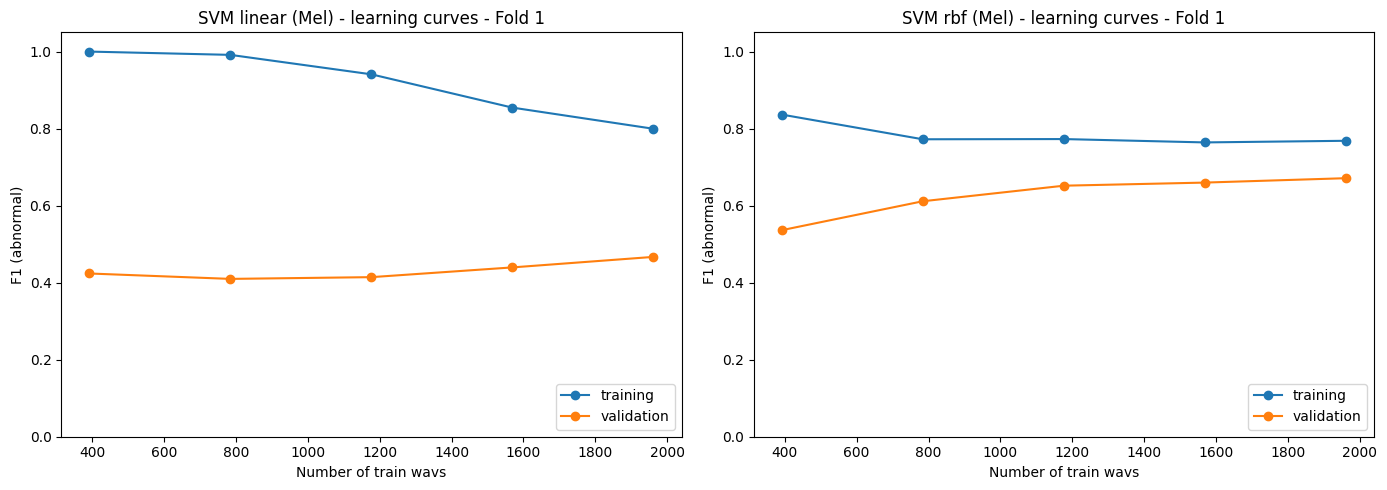

Fold 2 - linear : training F1 = 0.771 | validation F1 = 0.468 (with all its train wavs)
Fold 2 - rbf : training F1 = 0.763 | validation F1 = 0.622 (with all its train wavs)


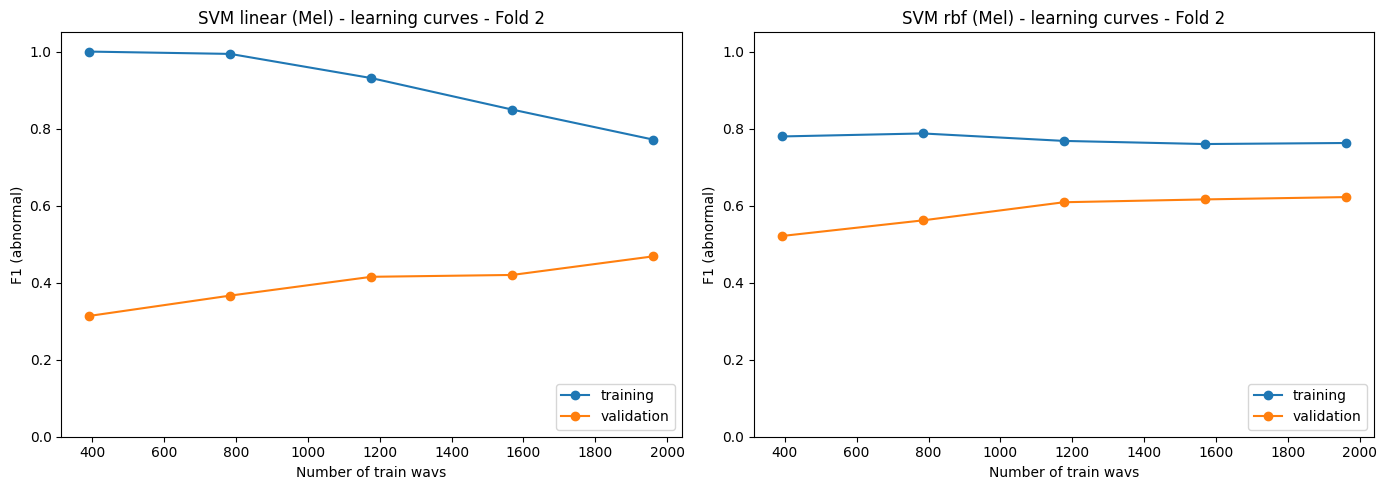

Fold 3 - linear : training F1 = 0.782 | validation F1 = 0.447 (with all its train wavs)
Fold 3 - rbf : training F1 = 0.786 | validation F1 = 0.622 (with all its train wavs)


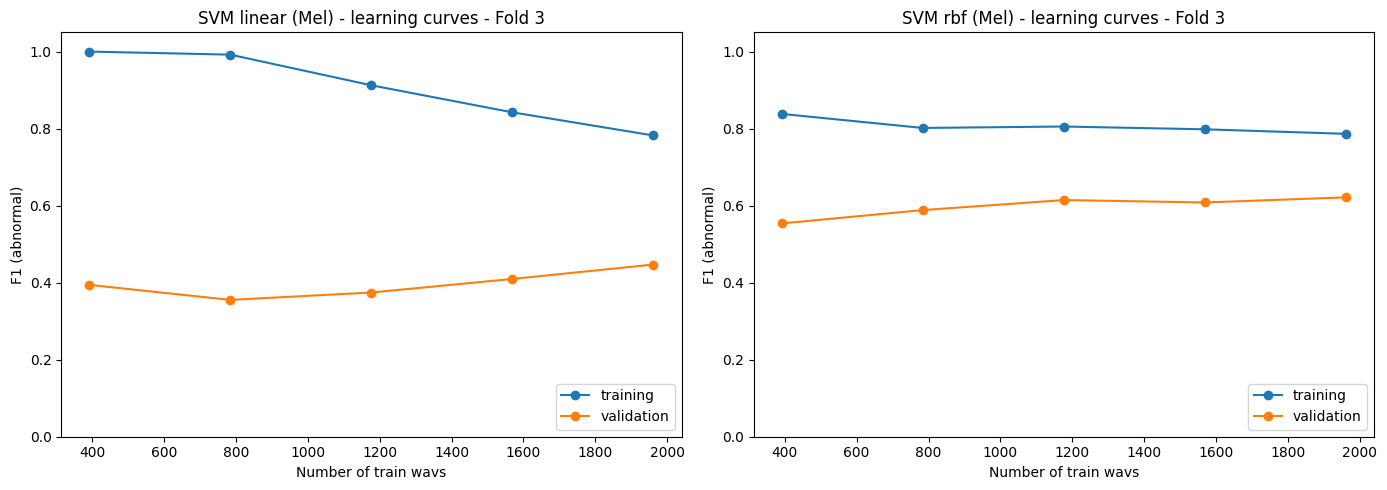

In [16]:
# ==================== Training vs validation: the learning curves (the same 3 folds) ====================
# For each fold, the SVM learns on 20%, 40%, 60%, 80% and 100% of its train wavs. Each time we look at its F1
# (abnormal) on these train wavs (= training) and on the third of the wavs it never saw (= validation).
#   - a big gap between the 2 curves = overfitting (the SVM learns its train wavs by heart)
#   - the validation curve still goes up at the end = more wavs would help
# shuffle=True: our wavs are sorted (all the abnormal ones first), so they are mixed before taking the 20%, 40%, ...
# It takes a few minutes: 2 kernels x 5 sizes x 3 folds = 30 SVMs.
X_mel_train = features[best_seconds][~is_test]

curves = {}    # the learning curves of each kernel
for kernel in kernels:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, class_weight="balanced"))    # scaler learned on the train wavs only
    sizes, train_scores, val_scores = learning_curve(model, X_mel_train, y_train, cv=kfold, scoring="f1",
                                                     train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
                                                     shuffle=True, random_state=0)
    curves[kernel] = (sizes, train_scores, val_scores)    # train_scores, val_scores: 1 row per size, 1 column per fold

# 1 figure per fold: the learning curves of this fold alone (linear | rbf)
for fold in range(3):
    plt.figure(figsize=(14, 5))
    place = 1
    for kernel in kernels:
        sizes, train_scores, val_scores = curves[kernel]
        print("Fold", fold + 1, "-", kernel, ": training F1 = {:.3f} | validation F1 = {:.3f} (with all its train wavs)".format(
            train_scores[-1, fold], val_scores[-1, fold]))
        plt.subplot(1, 2, place)
        plt.plot(sizes, train_scores[:, fold], "o-", color="tab:blue", label="training")
        plt.plot(sizes, val_scores[:, fold], "o-", color="tab:orange", label="validation")
        plt.title("SVM " + kernel + " (Mel) - learning curves - Fold " + str(fold + 1))
        plt.xlabel("Number of train wavs")
        plt.ylabel("F1 (abnormal)")
        plt.ylim(0, 1.05)
        plt.legend(loc="lower right")
        place = place + 1
    plt.tight_layout()
    plt.savefig(plots_folder + "tp3_svm_learning_curve_fold" + str(fold + 1) + ".png")
    plt.show()

linear : with all the train wavs -> training F1 = 0.784 | validation F1 = 0.461 (mean of the 3 folds)
rbf : with all the train wavs -> training F1 = 0.773 | validation F1 = 0.638 (mean of the 3 folds)


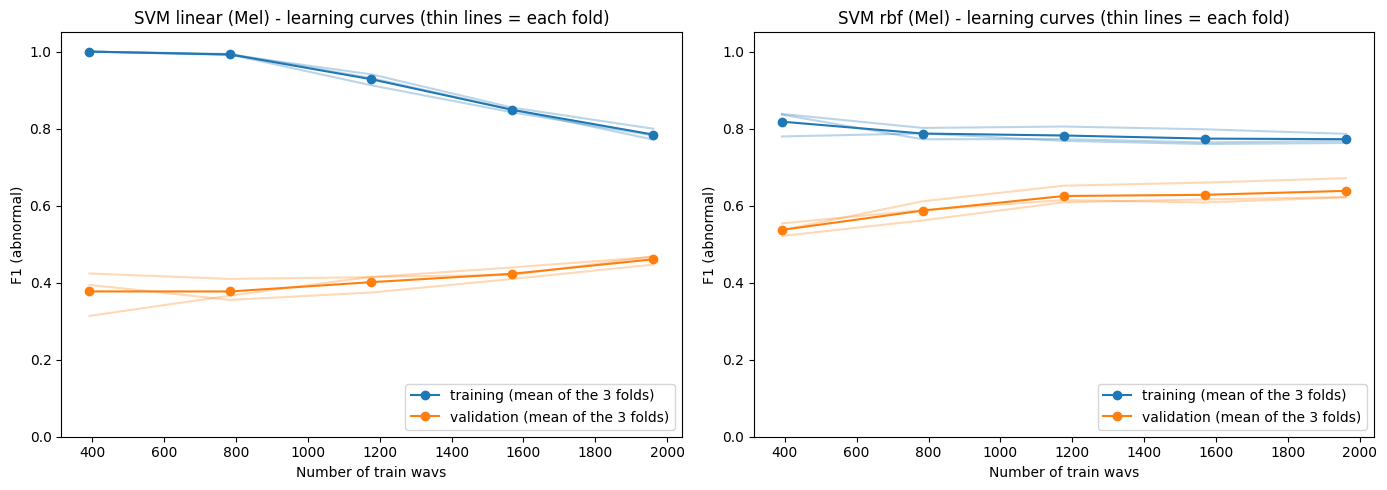

In [17]:
# The mean of the 3 folds: the same learning curves, thick lines = the mean (thin lines = each fold)
plt.figure(figsize=(14, 5))
place = 1
for kernel in kernels:
    sizes, train_scores, val_scores = curves[kernel]
    print(kernel, ": with all the train wavs -> training F1 = {:.3f} | validation F1 = {:.3f} (mean of the 3 folds)".format(
        train_scores[-1].mean(), val_scores[-1].mean()))

    plt.subplot(1, 2, place)
    for fold in range(3):    # thin lines: each fold
        plt.plot(sizes, train_scores[:, fold], color="tab:blue", alpha=0.3)
        plt.plot(sizes, val_scores[:, fold], color="tab:orange", alpha=0.3)
    plt.plot(sizes, train_scores.mean(axis=1), "o-", color="tab:blue", label="training (mean of the 3 folds)")
    plt.plot(sizes, val_scores.mean(axis=1), "o-", color="tab:orange", label="validation (mean of the 3 folds)")
    plt.title("SVM " + kernel + " (Mel) - learning curves (thin lines = each fold)")
    plt.xlabel("Number of train wavs")
    plt.ylabel("F1 (abnormal)")
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    place = place + 1

plt.tight_layout()
plt.savefig(plots_folder + "tp3_svm_learning_curves.png")    # also saved as an image file, to send it to MLflow
plt.show()

In [18]:
# ==================== STEP 5 - A second feature set: Zaineb's 72 features (merge of our 2 works) ====================
# On the WHOLE wav (no 5 s cut), n_fft = 512, hop = 128, 20 Mel bands:
#   duration, SNR (the function of TP1) | mean and std of each Mel band (20 + 20) | mean and std of 13 MFCC (13 + 13)
#   | mean and std of the spectral centroid (the "centre" of the frequencies) | mean and std of the ZCR (TP1)
# The mean of a band says how loud it is, the std says how much it changes in time (a murmur changes the spectrum).
# The same features are made by notebook 03 (decision tree): if it already made them, we load its file.
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)


def get_extended_features(signal):
    duration = len(signal) / SR
    snr = float(signaltonoise(signal / max(np.max(np.abs(signal)), 1e-10)))
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=20)
    S_DB = librosa.power_to_db(S, ref=np.max)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=13, n_fft=512, hop_length=128, n_mels=20)
    centroid = librosa.feature.spectral_centroid(y=signal, sr=SR, n_fft=512, hop_length=128)
    zcr = librosa.feature.zero_crossing_rate(signal, frame_length=512, hop_length=128)
    return ([duration, snr] + list(np.mean(S_DB, axis=1)) + list(np.std(S_DB, axis=1))
            + list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))
            + [np.mean(centroid), np.std(centroid), np.mean(zcr), np.std(zcr)])


cache_features = project_folder + "extended_features_72.data"
cache_names = project_folder + "tree_files.data"
if os.path.exists(cache_features) and os.path.exists(cache_names) and load_data(cache_names) == list(clean["name"]):
    X72 = np.array(load_data(cache_features))    # made by notebook 03, for the same wavs in the same order
    print("72 features loaded from", cache_features)
else:
    X72 = []
    for file in clean["file"]:
        signal, rate = librosa.load(file, sr=SR)
        X72.append(get_extended_features(signal))
    X72 = np.array(X72)
    save_data(list(X72), cache_features)
    save_data(list(clean["name"]), cache_names)
print("X72:", X72.shape)

# the same 3 folds of the 80% train part, rbf kernel (the best kernel of STEP 3-4)
folds_72 = evaluate_svm(X72[~is_test], y_train, "rbf")
predictions[("extended", "rbf")] = folds_72
run_ids[("extended", "whole wav", "rbf")] = log_validation_run("svm_rbf_extended72", "rbf", "extended features (72)",
                                                               "whole wav", X72.shape[1], folds_72)

# which feature set? The project rule: the highest mean validation RECALL of abnormal (the sick hearts found)
best_mel_kernel = summary.loc[best_seconds]["recall"].idxmax()    # the best kernel with the Mel features
candidates = {
    "Mel " + str(best_seconds) + " s (" + best_mel_kernel + ")": predictions[(best_seconds, best_mel_kernel)],
    "72 extended (rbf)": folds_72,
}
choice = []
for name in candidates:
    line = {"features": name}
    for metric in metrics:
        line[metric] = np.mean([f[metric] for f in candidates[name]])
    choice.append(line)
choice = pd.DataFrame(choice)
ipd.display(choice.round(3))

if choice["recall"][1] > choice["recall"][0]:
    chosen = {"features": "extended", "seconds": "whole wav", "kernel": "rbf", "X": X72,
              "text": "extended features (72)", "folds": folds_72}
else:
    chosen = {"features": "mel", "seconds": best_seconds, "kernel": best_mel_kernel, "X": features[best_seconds],
              "text": "mel spectrogram flatten (30 bands)", "folds": predictions[(best_seconds, best_mel_kernel)]}
print("Chosen SVM:", chosen["text"], "|", chosen["kernel"], "kernel | seconds:", chosen["seconds"])

72 features loaded from D:/MLOps_Project/extended_features_72.data
X72: (3681, 72)


🏃 View run svm_rbf_extended72_fold1 at: http://localhost:5000/#/experiments/2/runs/504a9e5b864f4dda93dfdc2047d15d38
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72_fold2 at: http://localhost:5000/#/experiments/2/runs/e41fa00c71b64916825f97d79b1d509b
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72_fold3 at: http://localhost:5000/#/experiments/2/runs/5515e9d90795440886e40492df69676c
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72 at: http://localhost:5000/#/experiments/2/runs/e8e7838ab52e4134864c7980c9dd1819
🧪 View experiment at: http://localhost:5000/#/experiments/2


,features,accuracy,precision,recall,f1,auc
0,Mel 2 s (rbf),0.787,0.516,0.840,0.639,0.879
1,72 extended (rbf),0.832,0.582,0.894,0.705,0.931


Chosen SVM: extended features (72) | rbf kernel | seconds: whole wav


--- Fold 1 : validation = 982 wavs
              precision    recall  f1-score   support

      normal       0.96      0.83      0.89       756
    abnormal       0.62      0.90      0.73       226

    accuracy                           0.85       982
   macro avg       0.79      0.87      0.81       982
weighted avg       0.88      0.85      0.86       982



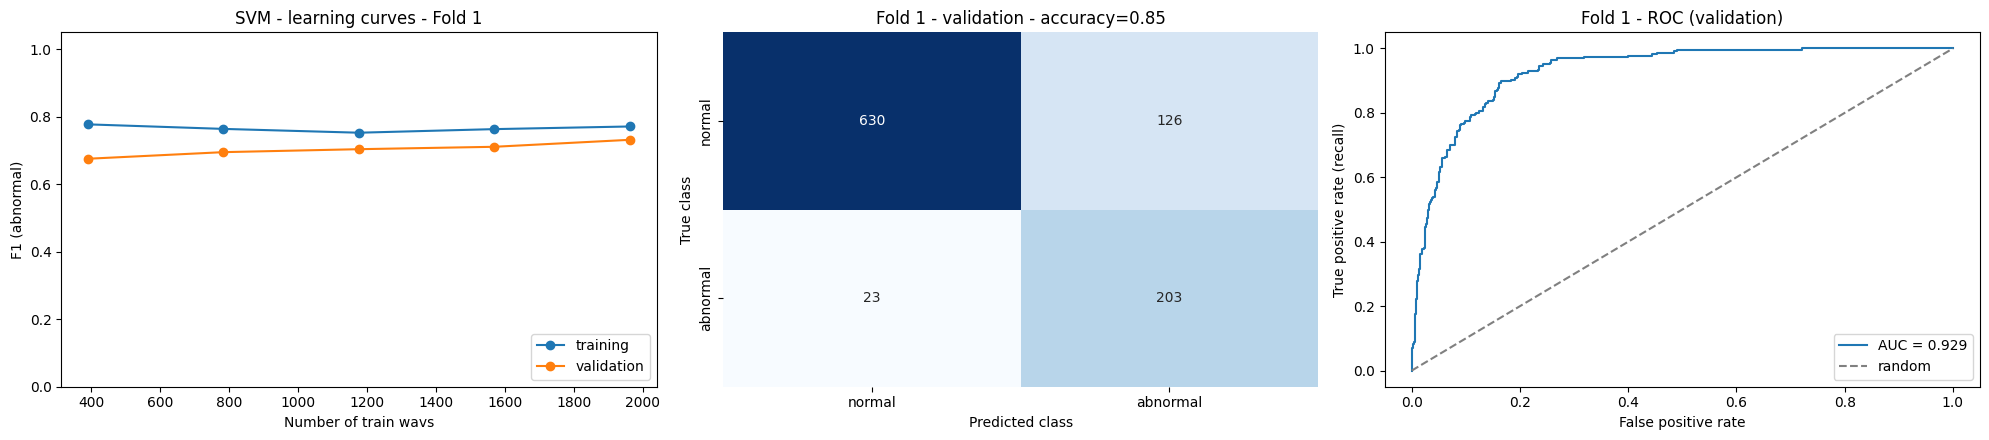

--- Fold 2 : validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.97      0.80      0.88       759
    abnormal       0.57      0.92      0.71       222

    accuracy                           0.83       981
   macro avg       0.77      0.86      0.79       981
weighted avg       0.88      0.83      0.84       981



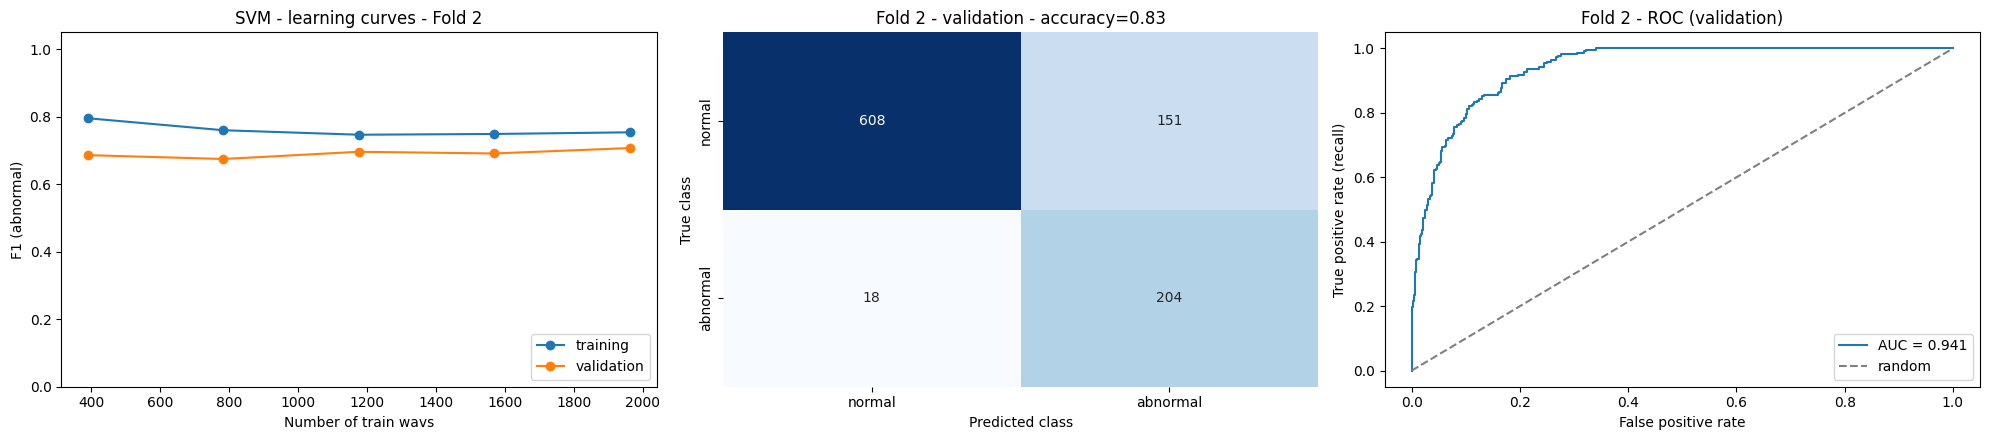

--- Fold 3 : validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.96      0.81      0.88       768
    abnormal       0.55      0.86      0.68       213

    accuracy                           0.82       981
   macro avg       0.75      0.84      0.78       981
weighted avg       0.87      0.82      0.83       981



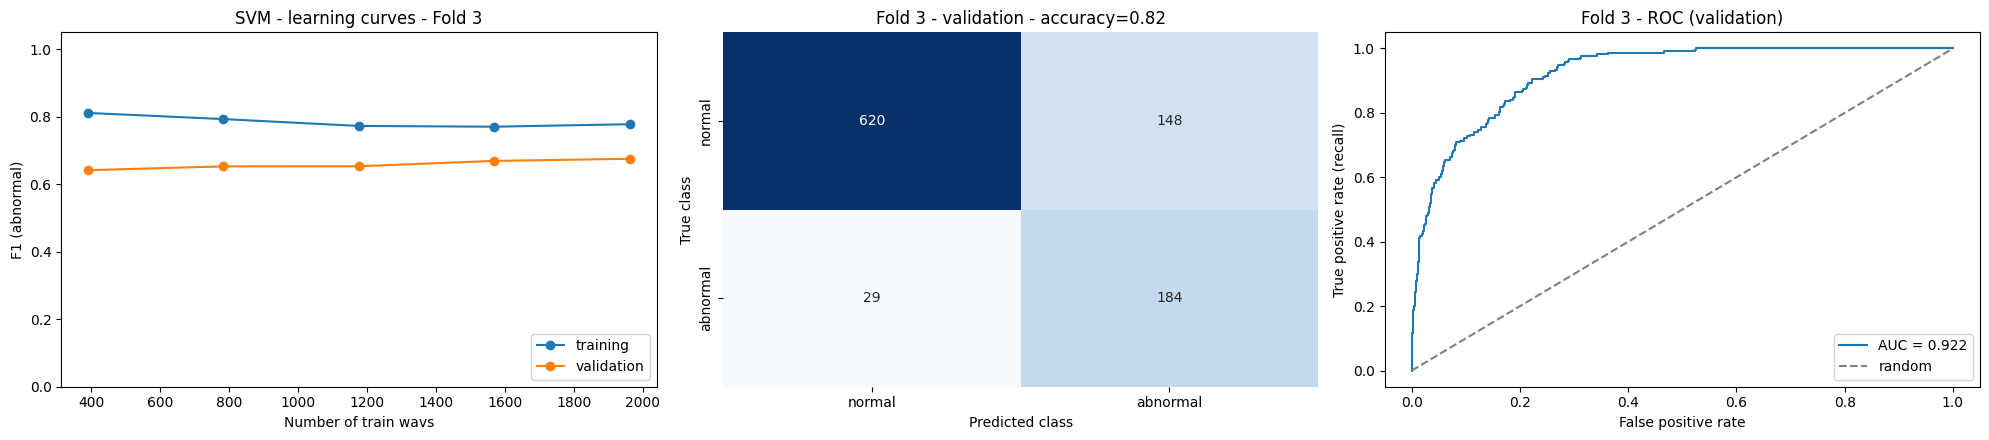

In [19]:
# ==================== STEP 6 - VALIDATION of the chosen SVM: the 3 folds in detail ====================
X_train = chosen["X"][~is_test]
X_test = chosen["X"][is_test]
chosen_folds = chosen["folds"]

# the learning curves of the chosen SVM (the same 3 folds)
model = make_pipeline(StandardScaler(), SVC(kernel=chosen["kernel"], class_weight="balanced"))
sizes, train_scores, val_scores = learning_curve(model, X_train, y_train, cv=kfold, scoring="f1",
                                                 train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True, random_state=0)

# 1 figure per fold: its learning curves + its confusion matrix + its ROC curve (validation wavs)
for f in chosen_folds:
    fold = f["fold"]
    print("--- Fold", fold, ": validation =", len(f["y_val"]), "wavs")
    print(classification_report(f["y_val"], f["y_pred"], target_names=["normal", "abnormal"]))
    plt.figure(figsize=(20, 4.5))
    plt.subplot(1, 3, 1)
    plt.plot(sizes, train_scores[:, fold - 1], "o-", color="tab:blue", label="training")
    plt.plot(sizes, val_scores[:, fold - 1], "o-", color="tab:orange", label="validation")
    plt.title("SVM - learning curves - Fold " + str(fold))
    plt.xlabel("Number of train wavs")
    plt.ylabel("F1 (abnormal)")
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    plt.subplot(1, 3, 2)
    PlotConfusionMatrix(confusion_matrix(f["y_val"], f["y_pred"]),
                        "Fold " + str(fold) + " - validation - accuracy=" + str(round(f["accuracy"], 2)))
    plt.subplot(1, 3, 3)
    plot_roc(f["y_val"], f["y_score"], "Fold " + str(fold) + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp3_svm_val_fold" + str(fold) + ".png")
    plt.show()

,fold,accuracy,precision,recall,f1,auc
0,1,0.848,0.617,0.898,0.732,0.929
1,2,0.828,0.575,0.919,0.707,0.941
2,3,0.820,0.554,0.864,0.675,0.922


Mean of the 3 folds (validation):
accuracy     0.832
precision    0.582
recall       0.894
f1           0.705
auc          0.931
dtype: float64


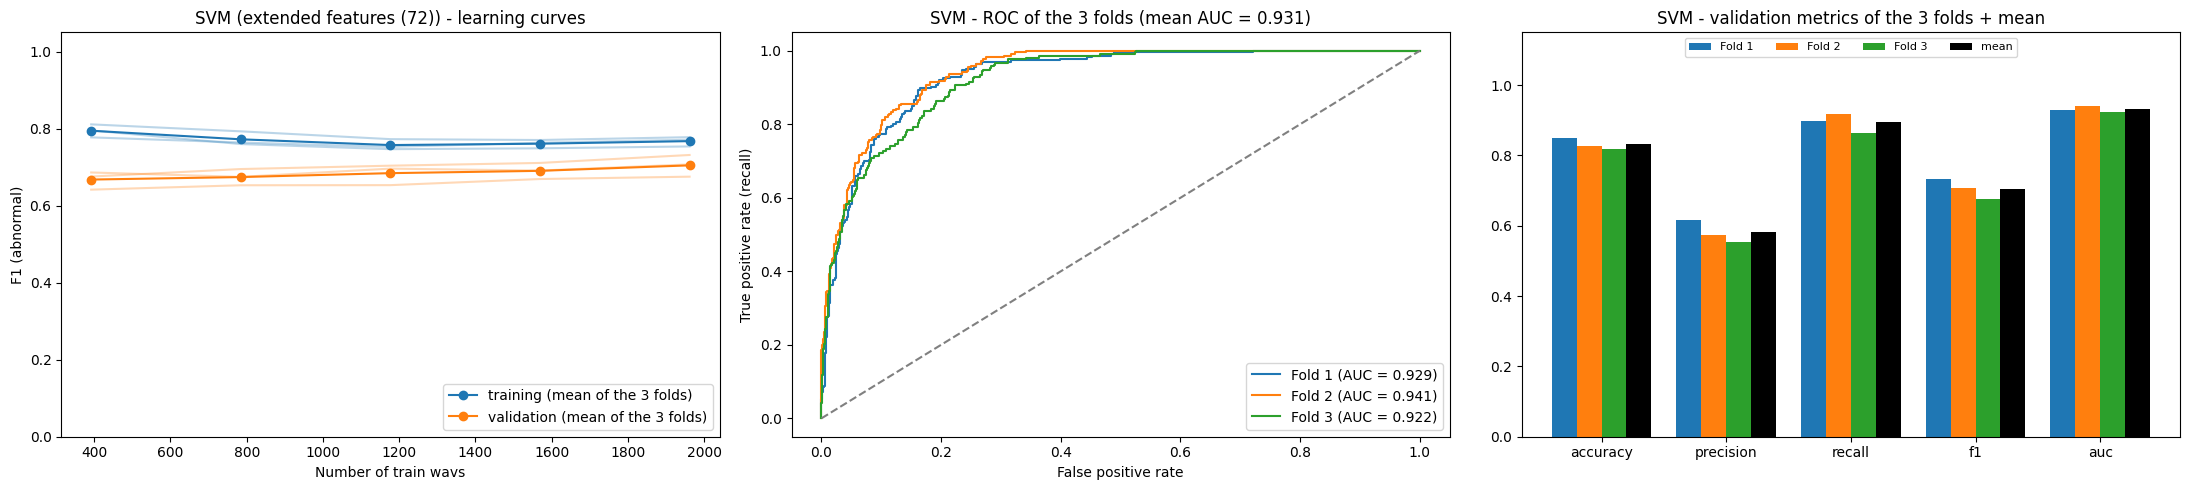

In [20]:
# The summary of the validation: the mean learning curves, the ROC of the 3 folds, the metrics of each fold + the mean
chosen_table = pd.DataFrame(chosen_folds)[["fold"] + metrics]
ipd.display(chosen_table.round(3))
print("Mean of the 3 folds (validation):")
print(chosen_table[metrics].mean().round(3))

plt.figure(figsize=(22, 5))
plt.subplot(1, 3, 1)
for fold in range(3):    # thin lines: each fold
    plt.plot(sizes, train_scores[:, fold], color="tab:blue", alpha=0.3)
    plt.plot(sizes, val_scores[:, fold], color="tab:orange", alpha=0.3)
plt.plot(sizes, train_scores.mean(axis=1), "o-", color="tab:blue", label="training (mean of the 3 folds)")
plt.plot(sizes, val_scores.mean(axis=1), "o-", color="tab:orange", label="validation (mean of the 3 folds)")
plt.title("SVM (" + chosen["text"] + ") - learning curves")
plt.xlabel("Number of train wavs")
plt.ylabel("F1 (abnormal)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")

plt.subplot(1, 3, 2)
for f in chosen_folds:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(f["y_val"], f["y_score"])
    plt.plot(false_positive_rate, true_positive_rate, label="Fold " + str(f["fold"]) + " (AUC = {:.3f})".format(f["auc"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("SVM - ROC of the 3 folds (mean AUC = {:.3f})".format(chosen_table["auc"].mean()))
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")

plt.subplot(1, 3, 3)
x = np.arange(len(metrics))
for i in range(3):
    plt.bar(x - 0.3 + 0.2 * i, chosen_table.loc[i, metrics], width=0.2, label="Fold " + str(i + 1))
plt.bar(x + 0.3, chosen_table[metrics].mean(), width=0.2, color="black", label="mean")
plt.xticks(x, metrics)
plt.ylim(0, 1.15)
plt.title("SVM - validation metrics of the 3 folds + mean")
plt.legend(loc="upper center", ncol=4, fontsize=8)

plt.tight_layout()
plt.savefig(plots_folder + "tp3_svm_val_summary.png")
plt.show()

              precision    recall  f1-score   support

      normal       0.97      0.83      0.89       572
    abnormal       0.60      0.92      0.73       165

    accuracy                           0.85       737
   macro avg       0.79      0.87      0.81       737
weighted avg       0.89      0.85      0.86       737



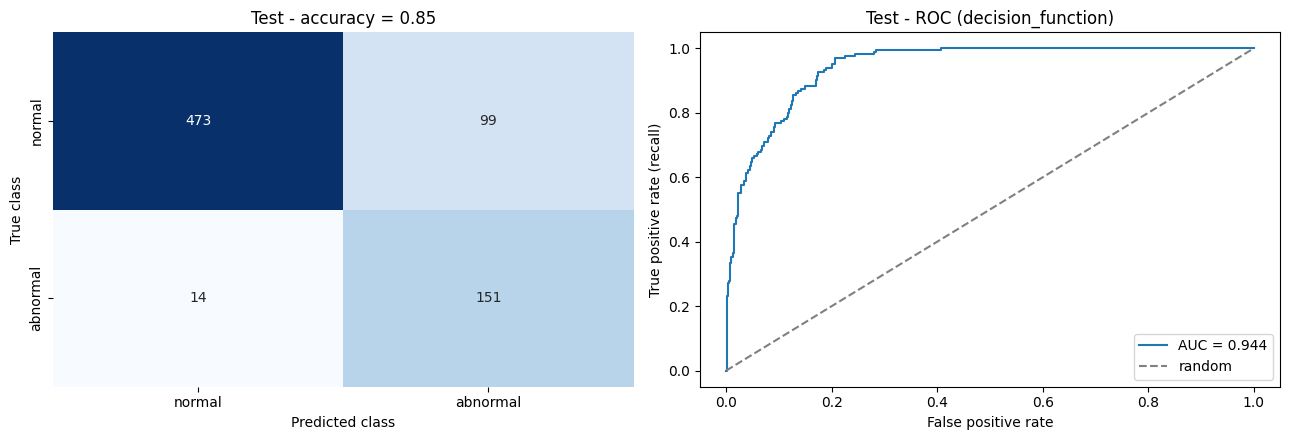

In [21]:
# ==================== STEP 7 - TEST: the final SVM learns on the 80% part, then is tested ONCE on the 20% ====================
# make_pipeline = the scaler + the SVM in ONE object, so later the audio engine can use it in one step
final_model = make_pipeline(StandardScaler(), SVC(kernel=chosen["kernel"], class_weight="balanced"))
final_model.fit(X_train, y_train)

y_test_pred = final_model.predict(X_test)
y_test_score = final_model.decision_function(X_test)
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_test_score)
test_results = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
    "auc": auc(false_positive_rate, true_positive_rate),
}
report = classification_report(y_test, y_test_pred, target_names=["normal", "abnormal"])
print(report)
with open(plots_folder + "tp3_svm_test_report.txt", "w") as f:
    f.write("SVM (" + chosen["text"] + ", " + chosen["kernel"] + ") - test set (" + str(len(y_test))
            + " wavs never seen)\n\n" + report)

# ONE test figure: the confusion matrix and the ROC curve of the test wavs
plt.figure(figsize=(13, 4.5))
plt.subplot(1, 2, 1)
PlotConfusionMatrix(confusion_matrix(y_test, y_test_pred), "Test - accuracy = {:.2f}".format(test_results["accuracy"]))
plt.subplot(1, 2, 2)
plot_roc(y_test, y_test_score, "Test - ROC (decision_function)")
plt.tight_layout()
plt.savefig(plots_folder + "tp3_svm_test.png")
plt.show()

In [22]:
# ==================== MLflow: the test results, the figures and the final model, in the run of the chosen SVM ====================
run_id = run_ids[(chosen["features"], chosen["seconds"], chosen["kernel"])]
with mlflow.start_run(run_id=run_id):    # we open the run of STEP 3 / STEP 5 again
    mlflow.set_tag("final", "yes")
    mlflow.log_param("protocol", "choices + 3 folds on the 80% train part (validation), final SVM tested on the 20%")
    mlflow.log_param("n_test", len(y_test))
    for metric in metrics:
        mlflow.log_metric("test_" + metric, test_results[metric])

    # the figures: plots/validation/ (the 3 folds and the studies) and plots/test/
    mlflow.log_artifact(plots_folder + "tp3_svm_figure.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp3_svm_learning_curves.png", artifact_path="plots/validation")
    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp3_svm_val_fold" + str(fold) + ".png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp3_svm_val_summary.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp3_svm_test.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp3_svm_test_report.txt", artifact_path="plots/test")

    # the final model (trained on the 80% part, the one that was tested): exported to ONNX by notebook 05
    mlflow.sklearn.log_model(final_model, "model", input_example=X_train[:5].astype(np.float32))

    # each fold run gets its figure
    fold_runs = mlflow.search_runs(experiment_names=["audio_benchmark_final"],
                                   filter_string="tags.mlflow.parentRunId = '" + run_id + "'")
    for i in range(len(fold_runs)):
        fold = int(fold_runs["params.fold"].iloc[i])
        with mlflow.start_run(run_id=fold_runs["run_id"].iloc[i], nested=True):
            mlflow.log_artifact(plots_folder + "tp3_svm_val_fold" + str(fold) + ".png", artifact_path="plots/validation")

print("Final SVM:", chosen["text"], "| test recall = {:.3f} | test F1 = {:.3f}".format(test_results["recall"],
                                                                                     test_results["f1"]))

🏃 View run svm_rbf_extended72_fold3 at: http://localhost:5000/#/experiments/2/runs/5515e9d90795440886e40492df69676c
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72_fold2 at: http://localhost:5000/#/experiments/2/runs/e41fa00c71b64916825f97d79b1d509b
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72_fold1 at: http://localhost:5000/#/experiments/2/runs/504a9e5b864f4dda93dfdc2047d15d38
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run svm_rbf_extended72 at: http://localhost:5000/#/experiments/2/runs/e8e7838ab52e4134864c7980c9dd1819
🧪 View experiment at: http://localhost:5000/#/experiments/2


Final SVM: extended features (72) | test recall = 0.915 | test F1 = 0.728
